In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.tree import plot_tree

In [3]:
np.random.seed(42)

fruit_data = {
    'Apple':  [170, 80, 40, 180, 7, 8],
    'Banana': [120, 220, 210, 25, 9, 3],
    'Orange': [160, 230, 130, 20, 8, 6],
    'Grapes': [5, 110, 60, 90, 6, 3],
    'Mango':  [200, 180, 100, 30, 9, 5]
}

rows = []

for fruit, values in fruit_data.items():
    for i in range(40):
        weight, red, green, blue, sweetness, texture = values

        rows.append([
            max(1, np.random.normal(weight, 10)),
            np.clip(np.random.normal(red, 10), 0, 255),
            np.clip(np.random.normal(green, 10), 0, 255),
            np.clip(np.random.normal(blue, 10), 0, 255),
            np.clip(np.random.normal(sweetness, 0.5), 1, 10),
            np.clip(np.random.normal(texture, 0.5), 1, 10),
            fruit
        ])

data = pd.DataFrame(rows, columns=[
    'Weight', 'Red', 'Green', 'Blue',
    'Sweetness', 'Texture', 'Fruit'
])

print(data.shape)
print(data.head())

(200, 7)
       Weight        Red      Green        Blue  Sweetness   Texture  Fruit
0  174.967142  78.617357  46.476885  195.230299   6.882923  7.882932  Apple
1  185.792128  87.674347  35.305256  185.425600   6.768291  7.767135  Apple
2  172.419623  60.867198  22.750822  174.377125   6.493584  8.157124  Apple
3  160.919759  65.876963  54.656488  177.742237   7.033764  7.287626  Apple
4  164.556173  81.109226  28.490064  183.756980   6.699681  7.854153  Apple


In [5]:
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

In [7]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=41,
    stratify=y
)

In [9]:
sc = StandardScaler()

x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [11]:
model = RandomForestClassifier(
    n_estimators=10,
    criterion='entropy',
    random_state=0
)

model.fit(x_train, y_train)

y_pred = model.predict(x_test)

In [13]:
print('Random Forest Classifier')

conf_mat = metrics.confusion_matrix(
    y_test, y_pred,
    labels=model.classes_
)

print('\nConfusion Matrix:\n', conf_mat)

accuracy = accuracy_score(y_test, y_pred)

print('Accuracy Score:', accuracy)
print('Accuracy in Percentage:', round(accuracy * 100, 2), '%')

print('\nClassification Report:\n')
print(metrics.classification_report(y_test, y_pred))

Random Forest Classifier

Confusion Matrix:
 [[12  0  0  0  0]
 [ 0 12  0  0  0]
 [ 0  0 12  0  0]
 [ 0  0  0 12  0]
 [ 0  0  0  0 12]]
Accuracy Score: 1.0
Accuracy in Percentage: 100.0 %

Classification Report:

              precision    recall  f1-score   support

       Apple       1.00      1.00      1.00        12
      Banana       1.00      1.00      1.00        12
      Grapes       1.00      1.00      1.00        12
       Mango       1.00      1.00      1.00        12
      Orange       1.00      1.00      1.00        12

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



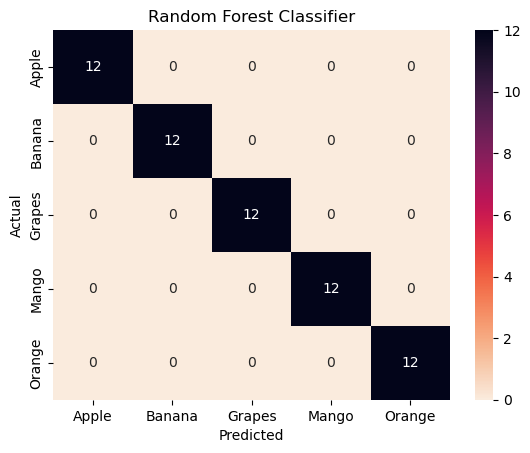

In [15]:
conf_mat = pd.crosstab(
    pd.Series(y_test, name='Actual'),
    pd.Series(y_pred, name='Predicted')
)

sns.heatmap(conf_mat, annot=True, fmt='d', cmap='rocket_r')

plt.title('Random Forest Classifier')
plt.show()

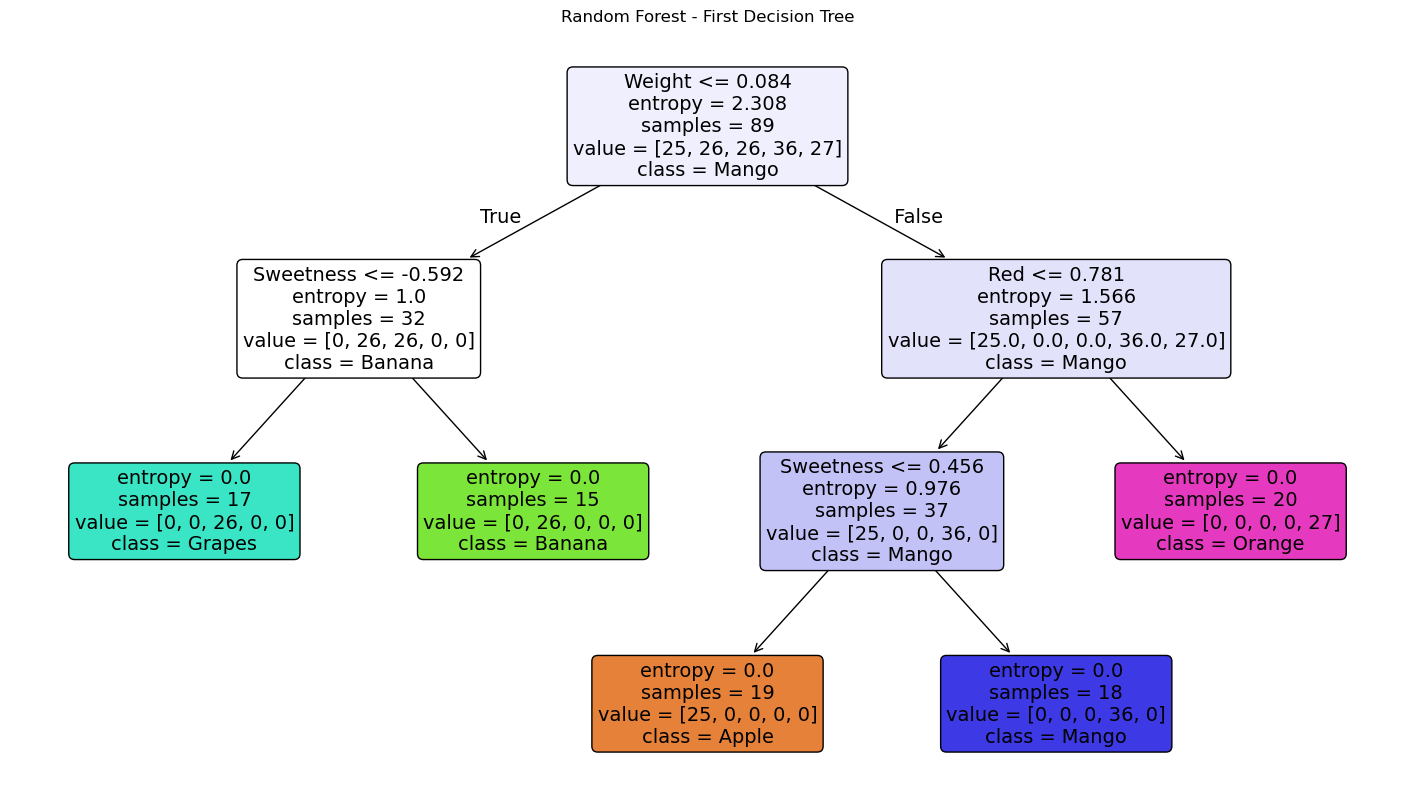

In [17]:
plt.figure(figsize=(18, 10))

plot_tree(
    model.estimators_[0],
    feature_names=[
        'Weight', 'Red', 'Green',
        'Blue', 'Sweetness', 'Texture'
    ],
    class_names=model.classes_,
    filled=True,
    rounded=True,
    max_depth=3
)

plt.title('Random Forest - First Decision Tree')
plt.show()

In [19]:
predictions = model.predict(x_test)

fruit_counts = pd.Series(predictions).value_counts()

print('Predicted fruit counts:')
print(fruit_counts)

print('\nFruit predicted most often:',
      fruit_counts.idxmax())

Predicted fruit counts:
Grapes    12
Mango     12
Apple     12
Orange    12
Banana    12
Name: count, dtype: int64

Fruit predicted most often: Grapes
